# 06 – Ausschnitt, Export und Bildunterschrift

**Was:** Aus dem Farbbild (Variante C) einen sauberen Ausschnitt ohne leere Ecken und verrauschte Ränder wählen, in mehreren Formaten exportieren und eine vollständige Bildunterschrift erzeugen.

**Warum:** Das Bild soll ohne dieses Repo verständlich und korrekt zitierbar sein: Was ist zu sehen, woher stammen die Daten, welche Farbe steht für welchen Filter, was wurde bearbeitet.

**Bewusst nicht enthalten:** lokale Eingriffe (Masken, Sterne verkleinern, selektive Sättigung). Dadurch bleibt die Bearbeitung vollständig durch die vorherigen Notebooks und die Parameterdateien beschrieben.

**Ergebnis:** Fertiges Farbbild von NGC 3132 (Variante C), Ausschnitt 1578 × 1578 px ≈ 1,66′ × 1,66′, Norden oben, Osten links. Exportiert als 16-bit TIFF und PNG (volle Qualität, `output/full_res/`) sowie als JPEG fürs Web mit englischer Bildunterschrift (`output/`).

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy.ndimage import distance_transform_edt, binary_fill_holes
import warnings
from astropy.io import fits
from astropy.wcs import WCS, FITSFixedWarning
import tifffile
from PIL import Image
from PIL.PngImagePlugin import PngInfo

warnings.simplefilter("ignore", FITSFixedWarning)

VARIANT = "C_physical"
BANDS = ["F090W", "F187N", "F212N", "F356W", "F405N", "F470N"]
REPROJ_DIR = Path("..") / "data" / "ngc3132_nircam_reproj_lw"
STRETCH_DIR = Path("..") / "data" / "ngc3132_nircam_stretched"
COLOR_FILE = Path("..") / "data" / "ngc3132_nircam_color" / f"ngc3132_{VARIANT}.npy"
FULL_DIR = Path("..") / "output" / "full_res"   # large files, ignored by git
WEB_DIR = Path("..") / "output"                  # web JPEG + caption, in git
FULL_DIR.mkdir(parents=True, exist_ok=True)

rgb = np.load(COLOR_FILE)
hdr = fits.getheader(REPROJ_DIR / "ngc3132_f090w_reproj_lw.fits", ext=0)
wcs = WCS(hdr)
print("colour image:", rgb.shape)

colour image: (3127, 3121, 3)


## 1. Gültiger, gut belichteter Bereich

Gleiche Logik wie in Etappe 4: gültig = in allen Filtern Daten (gesättigte Sternkerne zählen als gültig). Zusätzlich ein Sicherheitsabstand `MARGIN` zum Rand, weil dort laut Gewichtskarte (Etappe 2) weniger belichtet wurde und es stärker rauscht.

In [2]:
valid = np.ones(rgb.shape[:2], bool)
for b in BANDS:
    finite = np.isfinite(fits.getdata(REPROJ_DIR / f"ngc3132_{b.lower()}_reproj_lw.fits"))
    valid &= binary_fill_holes(finite)

MARGIN = 120   # px from the edge of the valid area (120 px ≈ 7.6″)
inner = distance_transform_edt(valid) > MARGIN
print(f"valid: {100 * valid.mean():.1f} %, inner (with margin): {100 * inner.mean():.1f} %")

valid: 55.3 %, inner (with margin): 44.5 %


## 2. Mitte des Nebels und größter quadratischer Ausschnitt

**Mitte:** Helligkeitsschwerpunkt der inneren Blase in F405N (ionisiertes Gas, recht symmetrisch). Die vierte Potenz betont die hellen Bereiche, damit schwache Filamente am Rand den Schwerpunkt nicht verschieben.

**Größe:** Ein Quadrat um diese Mitte wird so lange vergrößert, bis es an den Rand des gut belichteten Bereichs stößt (binäre Suche). Ein Quadrat passt zum fast runden Nebel; wer ein anderes Format möchte, kann `CENTER` und `HALF` unten von Hand setzen.

centre (y, x) = (1570, 1575), crop = 1578 x 1578 px = 1.66′ x 1.66′


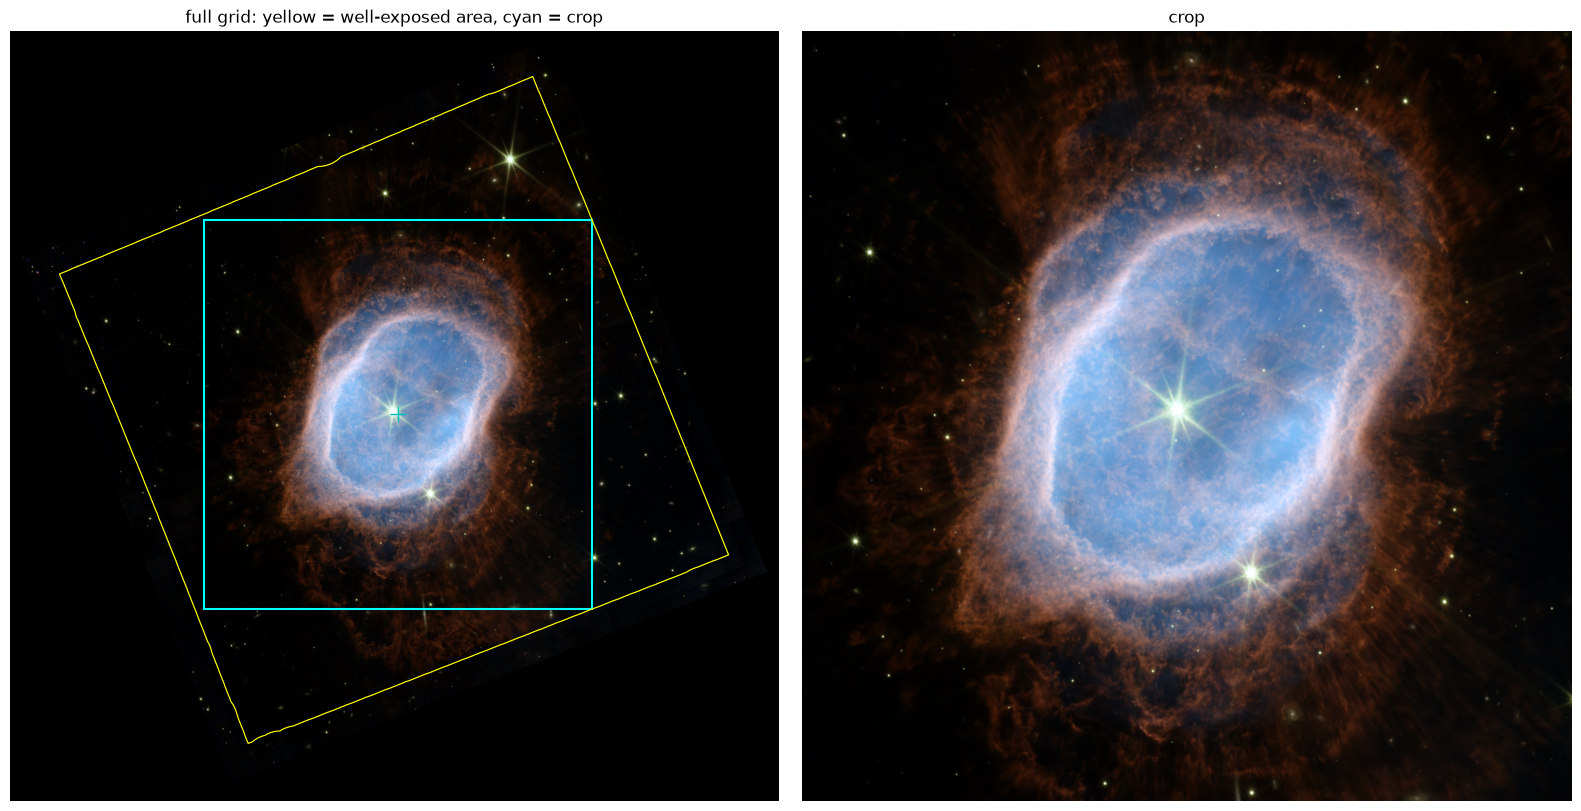

In [3]:
f405 = fits.getdata(STRETCH_DIR / "ngc3132_f405n_stretched.fits").astype(np.float64)
w = np.where(valid, f405, 0) ** 4
yy, xx = np.indices(w.shape)
CENTER = (int(round((w * yy).sum() / w.sum())), int(round((w * xx).sum() / w.sum())))

def square_ok(cy, cx, h):
    if cy - h < 0 or cx - h < 0 or cy + h > inner.shape[0] or cx + h > inner.shape[1]:
        return False
    return inner[cy - h:cy + h, cx - h:cx + h].all()

lo, hi = 50, max(inner.shape)
while lo < hi:                      # largest half-size that still fits
    mid = (lo + hi + 1) // 2
    lo, hi = (mid, hi) if square_ok(*CENTER, mid) else (lo, mid - 1)
HALF = lo
# CENTER, HALF = (1600, 1560), 900   # <- manual override if you prefer

cy, cx = CENTER
crop = np.s_[cy - HALF:cy + HALF, cx - HALF:cx + HALF]
print(f"centre (y, x) = {CENTER}, crop = {2 * HALF} x {2 * HALF} px "
      f"= {2 * HALF * 0.063 / 60:.2f}′ x {2 * HALF * 0.063 / 60:.2f}′")

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(rgb, origin="lower")
axes[0].contour(inner, levels=[0.5], colors="yellow", linewidths=0.8)
axes[0].add_patch(Rectangle((cx - HALF, cy - HALF), 2 * HALF, 2 * HALF, fill=False, ec="cyan", lw=1.5))
axes[0].plot(cx, cy, "c+", ms=12)
axes[0].set_title("full grid: yellow = well-exposed area, cyan = crop")
axes[1].imshow(rgb[crop], origin="lower")
axes[1].set_title("crop")
for ax in axes:
    ax.axis("off")
plt.tight_layout()

## 3. Orientierung prüfen

Für die Bildunterschrift wollen wir sicher sein: Wo ist Norden, wo Osten? Am Himmel (von unten gesehen) liegt Osten bei „Norden oben“ **links**, umgekehrt wie auf einer Landkarte. Wir prüfen es direkt mit dem WCS: Ein Schritt nach oben sollte die Deklination erhöhen (Norden), ein Schritt nach links die Rektaszension (Osten).

In [4]:
c0 = wcs.pixel_to_world(cx, cy)
up = wcs.pixel_to_world(cx, cy + 100)
left = wcs.pixel_to_world(cx - 100, cy)
north_up = up.dec > c0.dec
east_left = ((left.ra - c0.ra).wrap_at("180d").deg) > 0
print("centre:", c0.to_string("hmsdms", precision=1))
print("up = north:", bool(north_up), "| left = east:", bool(east_left))
ORIENTATION = "Norden oben, Osten links" if (north_up and east_left) else "BITTE PRÜFEN"
print(ORIENTATION)

centre: 10h07m01.6s -40d26m11.9s
up = north: True | left = east: True
Norden oben, Osten links


## 4. Bildunterschrift

Wird aus den Parameterdateien erzeugt, damit sie nicht von Hand auseinanderlaufen kann. Die Farbnamen sind grobe Beschreibungen der Farbtöne.

**Bitte prüfen und anpassen:**
- `AUTHOR`: unter welchem Namen du veröffentlichen willst.
- Die Credit-Zeile: Ich habe die übliche Form „NASA, ESA, CSA, STScI“ übernommen, wie sie auf den NASA-Seiten zu diesem Bild steht. Für die Weiterverwendung von JWST-Daten bitte die aktuellen Hinweise von STScI/MAST zur Nennung prüfen.
- Die Zuordnung der Filter zu Emissionslinien ist mein Kenntnisstand und sollte bei einer Veröffentlichung mit der JWST-Dokumentation abgeglichen werden.

In [7]:
AUTHOR = "Tritium13"   # how you want to be credited

COLOR_NAMES = {"F090W": "yellow", "F356W": "yellow-orange", "F187N": "light blue",
               "F405N": "blue", "F212N": "orange", "F470N": "red"}
CONTENT = {"F090W": "broadband: stars, scattered light",
           "F356W": "broadband: stars, nebula",
           "F187N": "ionised hydrogen (Paschen-α)",
           "F405N": "ionised hydrogen (Brackett-α)",
           "F212N": "molecular hydrogen (H2)",
           "F470N": "molecular hydrogen (H2)"}
ORIENTATION_EN = "north up, east left" if ORIENTATION.startswith("Norden") else "ORIENTATION TO BE CHECKED"
size_arcmin = 2 * HALF * 0.063 / 60

rows = "\n".join(f"| {b} | {COLOR_NAMES[b]} | {CONTENT[b]} |" for b in BANDS)
caption = f"""# Southern Ring Nebula (NGC 3132) – JWST NIRCam

Planetary nebula in the constellation Vela, observed on 3 June 2022 with the Near-Infrared Camera (NIRCam) of the James Webb Space Telescope as part of the Early Release Observations (programme 2733). Field of view ≈ {size_arcmin:.1f} × {size_arcmin:.1f} arcmin, {ORIENTATION_EN}.

## Colour assignment (chosen freely, grouped by physical origin, not by wavelength)

| Filter | Colour | Mainly traces |
|---|---|---|
{rows}

The recorded light is infrared; all colours are an assignment, not "true" colours.

## Processing

Calibrated stage-3 images (`_i2d.fits`) from MAST → common grid (0.063″/px, `reproject_adaptive`) → background subtraction from empty sky regions → asinh stretch per filter (each filter normalised to its own white point, so relative brightness between filters is not preserved) → additive colour mixing. Saturated star cores filled with white. No local adjustments. All parameters: `params/ngc3132_stretch.json`, `params/ngc3132_color.json`.

Known limitation: detector patterns (stripes, brightness steps) in F187N/F212N are suppressed by the black point, not removed.

## Credits

Data: NASA, ESA, CSA, STScI (JWST Early Release Observations, programme 2733), retrieved via MAST. Processing: {AUTHOR}.
"""
print(caption)

# Southern Ring Nebula (NGC 3132) – JWST NIRCam

Planetary nebula in the constellation Vela, observed on 3 June 2022 with the Near-Infrared Camera (NIRCam) of the James Webb Space Telescope as part of the Early Release Observations (programme 2733). Field of view ≈ 1.7 × 1.7 arcmin, north up, east left.

## Colour assignment (chosen freely, grouped by physical origin, not by wavelength)

| Filter | Colour | Mainly traces |
|---|---|---|
| F090W | yellow | broadband: stars, scattered light |
| F187N | light blue | ionised hydrogen (Paschen-α) |
| F212N | orange | molecular hydrogen (H2) |
| F356W | yellow-orange | broadband: stars, nebula |
| F405N | blue | ionised hydrogen (Brackett-α) |
| F470N | red | molecular hydrogen (H2) |

The recorded light is infrared; all colours are an assignment, not "true" colours.

## Processing

Calibrated stage-3 images (`_i2d.fits`) from MAST → common grid (0.063″/px, `reproject_adaptive`) → background subtraction from empty sky regions → asinh stretch

## 5. Export

Bildzeile 0 liegt bei `origin="lower"` unten; Bilddateien speichern die oberste Zeile zuerst. Deshalb wird vor dem Speichern vertikal gespiegelt (`flipud`), damit Norden auch in der Datei oben ist.

| Datei | Format | Zweck | Git |
|---|---|---|---|
| `output/full_res/…_16bit.tif` | 16 bit/Kanal, verlustfrei | Archiv, Weiterbearbeitung | nein |
| `output/full_res/…_full.png` | 8 bit/Kanal, verlustfrei | volle Auflösung zum Ansehen | nein |
| `output/…_web.jpg` | JPEG, max. 2000 px | Web, README | ja |
| `output/…_caption.md` | Markdown | Bildunterschrift | ja |

In [9]:
final = np.flipud(np.clip(rgb[crop], 0, 1))
stem = f"ngc3132_nircam_{VARIANT}"

# TIFF descriptions must be 7-bit ASCII -> transliterate (full UTF-8 caption goes into PNG and .md)
TO_ASCII = str.maketrans({"ä": "ae", "ö": "oe", "ü": "ue", "Ä": "Ae", "Ö": "Oe", "Ü": "Ue", "ß": "ss",
                          "′": "'", "″": '"', "≈": "~", "×": "x", "→": "->", "α": "alpha", "₂": "2",
                          "„": '"', "“": '"', "–": "-"})
tiff_desc = caption.translate(TO_ASCII).encode("ascii", "replace").decode("ascii")
tifffile.imwrite(FULL_DIR / f"{stem}_16bit.tif", (final * 65535 + 0.5).astype(np.uint16),
                 photometric="rgb", description=tiff_desc)

img8 = Image.fromarray((final * 255 + 0.5).astype(np.uint8))
info = PngInfo()
info.add_text("Description", caption)
img8.save(FULL_DIR / f"{stem}_full.png", pnginfo=info)

web = img8.copy()
web.thumbnail((2000, 2000), Image.Resampling.LANCZOS)
web.save(WEB_DIR / f"{stem}_web.jpg", quality=92)

(WEB_DIR / f"{stem}_caption.md").write_text(caption, encoding="utf-8")

for p in [FULL_DIR / f"{stem}_16bit.tif", FULL_DIR / f"{stem}_full.png",
          WEB_DIR / f"{stem}_web.jpg", WEB_DIR / f"{stem}_caption.md"]:
    print(f"{p.stat().st_size / 1e6:7.2f} MB  {p}")

  14.94 MB  ../output/full_res/ngc3132_nircam_C_physical_16bit.tif
   2.39 MB  ../output/full_res/ngc3132_nircam_C_physical_full.png
   0.33 MB  ../output/ngc3132_nircam_C_physical_web.jpg
   0.00 MB  ../output/ngc3132_nircam_C_physical_caption.md


## 6. Endkontrolle

Die exportierte Web-Version noch einmal laden und anzeigen, so wie andere sie sehen werden (jetzt ohne `origin="lower"`, weil die Datei bereits richtig herum gespeichert ist).

(1578, 1578) RGB


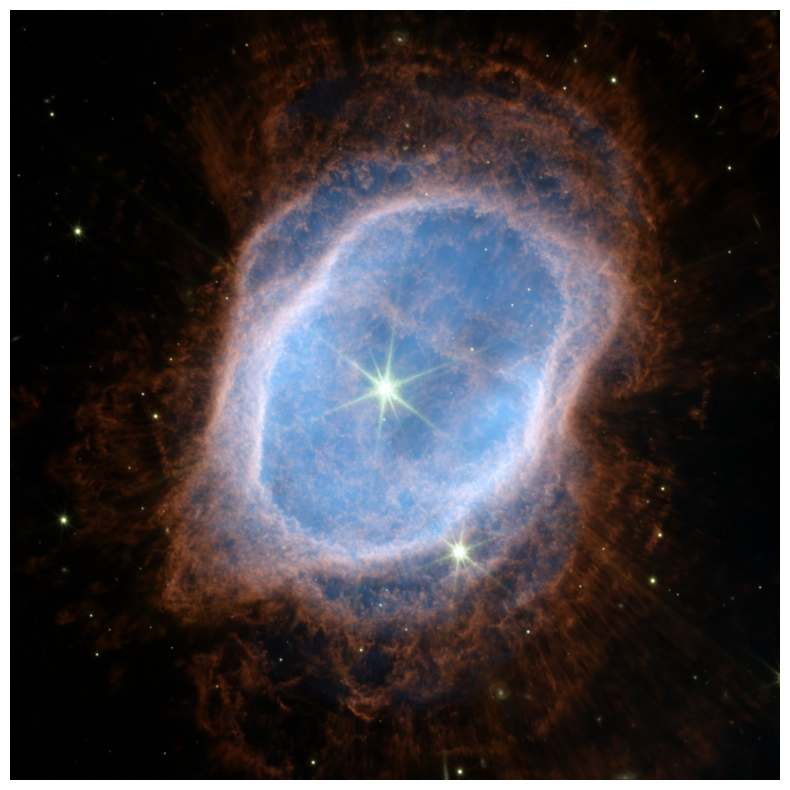

In [10]:
check = Image.open(WEB_DIR / f"{stem}_web.jpg")
print(check.size, check.mode)
plt.figure(figsize=(10, 10))
plt.imshow(check)
plt.axis("off");

## Fazit

- **Ausschnitt:** größtes Quadrat um den Schwerpunkt der inneren Blase (F405N), das vollständig im gut belichteten Bereich liegt (gültig in allen Filtern + 120 px Randabstand). Ergebnis: Mitte (y, x) = (1570, 1575), 1578 × 1578 px ≈ 1,66′. Keine leeren Ecken, keine verrauschten Randstreifen.
- **Orientierung** per WCS geprüft: Norden oben, Osten links (am Himmel umgekehrt zur Landkarte).
- **Export:** 16-bit TIFF (14,9 MB) und PNG (2,4 MB) in voller Auflösung, JPEG (0,33 MB) fürs Web. Bildunterschrift wird aus den Parameterdateien erzeugt und steht als Markdown neben dem Bild sowie in den Metadaten von PNG und TIFF.
- **Fehler und Lösung:** TIFF erlaubt in der Bildbeschreibung nur 7-bit-ASCII (Umlaute → Fehler). Lösung: Transliteration für TIFF, volle Fassung in PNG und `.md`. Bildunterschrift auf Englisch umgestellt (öffentliches Publikum).
- **Eindruck:** Innere Blase (ionisiertes Gas, blau) und äußere Schalen (molekularer Wasserstoff, rot-orange) klar getrennt, feine Klumpenstruktur sichtbar, mehrere Hintergrundgalaxien. Die Detektor-Muster aus F187N/F212N sind im Farbbild nicht mehr erkennbar.
- **Grenzen und Ideen:** Äußerste Schalen oben/unten leicht angeschnitten (begrenzt durch den gut belichteten Bereich). Zentralstern mit gelb-grünlichem Stich (gelbe Breitbandfilter in Variante C) → Variante D („LRGB“, weiße Sterne) als Option. Maßstab und Kompass könnten ergänzt werden.
- **Vor Veröffentlichung prüfen:** aktuelle Credit-Hinweise von STScI/MAST; Zuordnung der Filter zu Emissionslinien mit der JWST-Dokumentation abgleichen.

**Nächster Schritt:** Etappe 7 – Ring-Nebel (NGC 6720) mit derselben Pipeline, Funktionen in `src/` auslagern.